In [19]:
%pip install -q otter-grader

%pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://packagemanager.posit.co/pypi/latest/simple
Note: you may need to restart the kernel to use updated packages.


In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk2-task2-salmon.ipynb")

# Task 2: Wrangling Alaska salmon catch data 

## Instructions 

- First, update the following cell to have a link to *your* Homework 2 GitHub repository:

**UPDATE THIS LINK**

https://github.com/katefrankland/eds220-hwk2.git


- Review the [complete rubric for this task](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- **Every code cell should have a comment.** Err on the side of commenting too much for now. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.

## Acknowledgments

This exercise is based on the [Cleaning and Wrangling Data in R lesson by the NCEAS Learning Hub](https://learning.nceas.ucsb.edu/2023-06-delta/session_11.html).


> Halina Do-Linh, Carmen Galaz García, Matthew B. Jones, Camila Vargas Poulsen. 2023. Open Science Synthesis training Week 1. NCEAS Learning Hub & Delta Stewardship Council.


## About the data

In this task you will use simplified data from the Alaska Department of Fish & Game containing commercial salmon catch data from 1878 to 1997. The original data can be accessed from the KNB repository:

> [Mike Byerly. (2016). Alaska commercial salmon catches by management region (1886-1997).](https://knb.ecoinformatics.org/view/df35b.304.2) Gulf of Alaska Data Portal. df35b.304.2.

The simplified dataset is in CSV format in the homework repository and has the following columns:

| Column | Description |
| ------ | ----------- | 
| Region | Region code |
| Year | Year fish were caught |
| notesRegCode | Notes and comments |
| Species | Species of salmon caught |
| Catch | Commercial catches of salmon species (in thousands of fish) |

## COMPLETE WORKFLOW

You will use the next code cell to complete the last exercise in the task. Leave it blank for now. 

In [42]:
# FINAL CODE

# Import the libraries 
import pandas as pd 
import numpy as np 

# Load in the data 
catch_data = pd.read_csv('data/salmon_data.csv') 

# Changing the value from I to 1 
catch_data.loc[catch_data["Catch"] == "I", "Catch"] = "1"


# Creating a new data frame showing the average salmon catch per region 
avg_region = catch_data.groupby("Region")["Catch"].mean()


# Code for creating the plot 

salmon_barplot = (avg_region.sort_values().plot(
    kind = "bar", 
    color = "hotpink",
    ylabel = "Average Salmon Catch (Thousands)",
    xlabel = "Alaskan Region",
    title = "Estimated Average Salmon Catches by Alaskan Region"
))

salmon_barplot

TypeError: agg function failed [how->mean,dtype->object]

## 1

a. Use this code cell to import the data from the `salmon_data.csv` as `catch_data`. Look at the head of the data frame. 

<!-- BEGIN QUESTION -->



In [2]:
# a.

# Import libraries 
import pandas as pd 
import numpy as np 

# Load in the data 
catch_data = pd.read_csv('data/salmon_data.csv') 
catch_data.head()


,Region,Year,notesRegCode,Species,Catch
0,SSE,1886,NaN,Chinook,0
1,SSE,1887,NaN,Chinook,0
2,SSE,1888,NaN,Chinook,0
3,SSE,1889,NaN,Chinook,0
4,SSE,1890,NaN,Chinook,0


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use this code cell to make some other preliminary data exploration of your choosing.

In [61]:
# b.

# Looking at the data information 
print(catch_data.info())

# Looking for the number of rows/columns
print(catch_data.shape)

# Looking for unique values 
catch_data['Species'].unique()
catch_data['Region'].unique()

<class 'pandas.DataFrame'>
RangeIndex: 8540 entries, 0 to 8539
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Region        8540 non-null   str  
 1   Year          8540 non-null   int64
 2   notesRegCode  1415 non-null   str  
 3   Species       8540 non-null   str  
 4   Catch         8540 non-null   str  
dtypes: int64(1), str(4)
memory usage: 333.7 KB
None
(8540, 5)


<StringArray>
['SSE', 'NSE', 'YAK', 'GSE', 'BER', 'COP', 'PWS', 'CKI', 'BRB', 'KSK', 'YUK',
 'NRS', 'KTZ', 'KOD', 'CHG', 'SOP', 'ALU', 'NOP']
Length: 18, dtype: str

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Use this markdown cell to explain why you decided to do the exploration in b. and what information you obtained from doing it.

- To explore the data, I used the Python tools **.info, .shape, and .unique**.
- The **.info** method shows the column names, data types, and the amount of non null values in the columns. The **.shape** attribute shows us that there are 8540 rows and 5 columns, so we have an idea of the amount of data that we are working with. Using **.unique()**, for the Species, it tells us that there are five salmon species, being Chinook, Sockeye, Coho, Pink, and Chum. Using **.unique** for the Region, we see the different region names in Alaska that this dataset is observing. These tools help us understand the contents of the dataset before moving on to the next steps for data analysis.
  

<!-- END QUESTION -->

## 2
In the next cell:

a. Store the unique values of the `notesRegCode` column in the `notes_unique` variable. 

In [3]:
notes_unique = catch_data['notesRegCode'].unique() # Looking at the unique values for each column 
print(notes_unique) # Printing the result  

[nan 'Includes Yakutat catches' 'Yakutat catch included in No SE AK catch'
 'Estimated from canned production, probably sockeye' 'No fishery'
 'Bering River catches included in Copper River catches'
 'Includes Bering River catches; estimated from canned'
 'Includes Bering River catches'
 'Coho and pink catch estimated from canned production'
 'Includes Bering River; coho and pink estimated fro canned'
 'Pink catch estimated from canned'
 'Includes Bering River; coho pink and chum estimated from canned'
 'Includes Bering River; pink estimated from canned'
 'Includes Bering River; pink and chum estimated from canned'
 'Includes Copper River catches'
 'Includes Copper River catches; coho catch porbably mostly pinks'
 'Eshamy District only' 'Estimated from canned; excludes Resurrection Bay'
 'Estimated from canned production' 'No Resurrection Bay fishery'
 'Resurrection bay contribution estimated from canned production'
 'No reported catch'
 'Sockeye and pink and 9922 chum from Port Claren

In [4]:
grader.check("q2a")

q2a results: All test cases passed!

b. Update the data frame so it doesn't include the `notesRegCode` column. Verify the column is no longer in the data frame.

In [5]:
catch_data = catch_data.drop(columns = 'notesRegCode') # Dropping the notesRegCode column 
catch_data.columns # Viewing the columns to see if it was removed 

Index(['Region', 'Year', 'Species', 'Catch'], dtype='object')

In [6]:
grader.check("q2b")

q2b results: All test cases passed!

<!-- BEGIN QUESTION -->

## 3
Does each column have the expected data type? Use this code cell to obtain this information and write your answer in the next markdown cell.


In [7]:
catch_data.dtypes

Region     object
Year        int64
Species    object
Catch      object
dtype: object

The Region, Species, and Year columns all have the correct data types. However. the Catch column is storeed as a string. There are numerical values in the Catch column, so this column should be cleaned to make sure that the entires that are not numbers are edited. 

<!-- END QUESTION -->

## 4 
The following cell shows a first attempt at updating the `Catch` column to be of data type `int64` instead of `object`. Converting from one data type to another is often called **casting**. 

To do it we use the [`astype()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.astype.html) method for `pandas.Series`. The `astype()` method does not modify the `pandas.Series` in place.

Run the next cell and read the end of the error message closely.

In [11]:
catch_data['Catch'].astype('int64')

ValueError: invalid literal for int() with base 10: 'I'

## 5 

The previous error tells us there is a value 'I' (as in the letter 'I') that could not be converted to integer type. It turns out the original data set was created from a PDF which was automatically converted into a CSV file and this 'I' value should be 1.

In the next cell find the row(s) causing this issue. Show the filtered row(s) as the output. Store your answer in the `catch_I` variable. `catch_I` should have one observation and contain the following columns: Region, Year, Species, Catch. It should contain the original index number in order to pass the test. 

In [29]:
catch_I = catch_data[catch_data["Catch"] == "I"] # identifying the rows with I and filter 
catch_I # Displaying the filtered data 

,Region,Year,Species,Catch


In [30]:
grader.check("q5")

q5 results: All test cases passed!

## 6
In the next cell:

1. Update the value of I to 1.
2. Access the row you updated to verify the value was changed and store this single row in the `catch_1` variable. 

<!-- BEGIN QUESTION -->



In [34]:

catch_data.loc[catch_data["Catch"] == "I", "Catch"] = "1" # Changing the value from I to 1 

catch_1 = catch_data.loc[400] # finding the 400 row and storing it in catch_1 

catch_1 # Print catch_1


Region         GSE
Year          1955
Species    Chinook
Catch            1
Name: 400, dtype: object

<!-- END QUESTION -->

## 7
In the next cell:

1. Update the `Catch` column in `catch_data` to be of type `int64`.
2. Confirm you have updated the data type. Store the type of the `Catch` column in the `catch_column_type` variable.

In [35]:
catch_data["Catch"] = catch_data["Catch"].astype("int64") # Changing the Catch column to be an integer 

catch_column_type = catch_data["Catch"].dtype # Storing it into the catch_column_type variable

catch_column_type # Display the result 

dtype('int64')

In [14]:
grader.check("q7")

q7 results: All test cases passed!

<!-- BEGIN QUESTION -->

## 8
Create a data frame with the average salmon catch per region. HINT: use `groupby()`. Store your data frame in a new variable called `avg_region`


In [40]:
avg_region = catch_data.groupby("Region")["Catch"].mean() # Creating a new data frame showing the average salmon catch per region 
avg_region # Display the result 

Region
ALU      40.383908
BER      16.372549
BRB    2709.796491
CHG     315.487273
CKI     683.571429
COP     179.223404
GSE     133.841463
KOD    1528.350000
KSK      67.642353
KTZ      18.836145
NOP     229.493478
NRS      51.502703
NSE    1825.020870
PWS    1419.236697
SOP    1110.942222
SSE    3184.660714
YAK      91.922917
YUK      68.645570
Name: Catch, dtype: float64

In [41]:
grader.check("q8")

q8 results: All test cases passed!

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 9 

Use the data frame you created in 8 to make a bar graph of the estimated average salmon catches by region from 1878 to 1997. The bars in the graph should be ordered by magnitude (increasing or decreasing is ok). Add a title to your graph and update the axes labels if needed (check the units for the salmon catch). 

<Axes: title={'center': 'Estimated Average Salmon Catches by Region'}, xlabel='Alaskan Region', ylabel='Average Salmon Catch (Thousands)'>

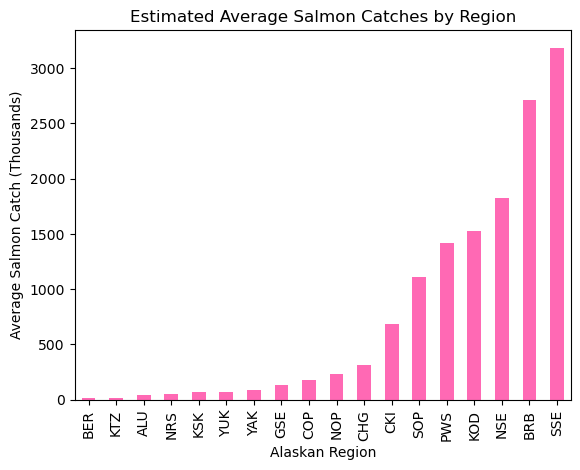

In [25]:
salmon_barplot = (avg_region.sort_values().plot(
    kind = "bar", 
    color = "hotpink",
    ylabel = "Average Salmon Catch (Thousands)",
    xlabel = "Alaskan Region",
    title = "Estimated Average Salmon Catches by Alaskan Region"
))

salmon_barplot

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 10

Write a brief description with key takeaways from the plot. Your answer should use the complete names for the management areas instead of their codes. You can find what each code stands for in the [original data repository](https://knb.ecoinformatics.org/view/df35b.304.2#df35b.303.1).

The key takeaways from this plot are that the SSE (Southern Southeast Alaska) and BRB (Bristol Bay) regions have the highest average catches, while many other management areas have far lower catches.  This shows that between 1878 to 1997, average catches varied greatly  across management areas in Alaska. 

<!-- END QUESTION -->

## 11

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the graph. The *only* output of this cell should be the graph you produced in the previous exercise. Further guidance on what to include in this final workflow is in the [assignment rubric](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0).

---

To double-check your work, the cell below will rerun all of the autograder tests.

In [ ]:
grader.check_all()